# Notebook 2 — Preprocessing

**Goal:** turn the raw records into one clean, time-aligned table that later notebooks can use.

**Input:** `data/raw/data.txt` (read-only)  
**Outputs:** `data/interim/sensor_records_flagged.parquet`, `data/processed/clean_sensor_data.parquet`, `normalization_parameters.json`, `preprocessing_metadata.json`, plus tables/figures.

## Decisions (all set in the config cell, all changeable)
| Step | Decision | Why |
|---|---|---|
| Which records | motes 1–54, valid timestamp, before **2004-03-22** | after ~03-22 the sensors fail (Notebook 1, daily plot): valid temperature drops from ~90% to ~0% by 03-25, so a time-based test set there would be almost empty |
| Bad values | **flagged**, raw kept, `*_clean` = NaN when invalid | suspicious values may be real sensor faults |
| Duplicates | keep first `(moteid, timestamp)` | none expected; check proves it |
| Time grid | 1-minute bins, mean of valid readings in the bin | median interval is ~33 s, so ≈1–2 readings per bin; one grid lets peers be compared at the same time |
| Missing values | **not interpolated**, left as NaN | filling gaps would invent data; missingness is information |
| Noise filtering | **none** | any smoothing risks erasing genuine events; the 1-minute average already reduces jitter |
| Split | chronological 70 / 15 / 15 | no random splitting on time series |
| Normalization | z-score, **fitted on train only** | prevents future information leaking into the past |

In [2]:
from pathlib import Path
import sys, hashlib, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# --- Find the project root (the folder that contains src/intel_utils.py) ---
_here = Path.cwd().resolve()
_roots = [p for p in [_here, *_here.parents] if (p / "src" / "intel_utils.py").exists()]
if not _roots:
    raise FileNotFoundError("Project root not found. Start Jupyter from inside the project folder "
                            "(the one containing the src/ folder).")
ROOT = _roots[0]
sys.path.insert(0, str(ROOT / "src"))
import intel_utils as u

RAW_FILE = ROOT / "data" / "raw" / "data.txt"
SEED = 42
np.random.seed(SEED)

def sha256(path, chunk=1 << 24):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()

if not RAW_FILE.exists():
    raise FileNotFoundError(f"Put the unzipped data.txt at: {RAW_FILE}")
RAW_HASH_BEFORE = sha256(RAW_FILE)
print("Project root:", ROOT)
print("Raw file    :", RAW_FILE, f"({RAW_FILE.stat().st_size/1e6:.1f} MB)")

# ------------------------- CONFIG -------------------------
END_TIME   = pd.Timestamp("2004-03-22 00:00:00")  # stop before the network-wide sensor failure (see Notebook 1)
GRID_FREQ  = "1min"
SPLIT_FRACTIONS = (0.70, 0.15, 0.15)              # train / validation / test (chronological)
# -----------------------------------------------------------
assert abs(sum(SPLIT_FRACTIONS) - 1) < 1e-9

OUT = ROOT / "outputs" / "notebook02"; FIG = ROOT / "figures" / "notebook02"
INTERIM = ROOT / "data" / "interim"; PROC = ROOT / "data" / "processed"
for p in (OUT, FIG, INTERIM, PROC):
    p.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

Project root: C:\AIoT_Research
Raw file    : C:\AIoT_Research\data\raw\data.txt (150.9 MB)


## 1. Load raw data and select records
Every excluded record is counted with a reason.

In [4]:
raw = u.load_raw(RAW_FILE)
n_raw = len(raw)

steps = []
cur = raw
def keep(mask, reason):
    global cur
    removed = int((~mask).sum())
    steps.append({"reason": reason, "records_removed": removed})
    cur = cur[mask]

keep(cur["moteid"].notna(),                 "no mote ID")
keep(cur["moteid"].between(1, 54),          "mote ID outside documented 1-54")
keep(cur["timestamp"].notna(),              "unparseable timestamp")
keep(cur["timestamp"] < END_TIME,           f"timestamp on/after {END_TIME}")

records = cur.copy()
records["moteid"] = records["moteid"].astype("int16")
exclusions = pd.DataFrame(steps)
print(exclusions.to_string(index=False))
print(f"\nraw rows: {n_raw:,}  ->  kept: {len(records):,}")
assert len(records) + exclusions["records_removed"].sum() == n_raw

                                reason  records_removed
                            no mote ID              526
       mote ID outside documented 1-54             9866
                 unparseable timestamp                4
timestamp on/after 2004-03-22 00:00:00           437916

raw rows: 2,313,682  ->  kept: 1,865,370


### 🔎 Interpretation — Record selection

This stage reduces the raw dataset from **2,313,682 records to 1,865,370 records**.

The removals are explicitly accounted for:

- **526** records have no mote ID.
- **9,866** use mote IDs outside the documented primary network (1–54).
- **4** have unparseable timestamps.
- **437,916** occur on/after **22 March 2004**, the configured cutoff.

The first three exclusions are data-integrity filtering. The last one is a **deliberate modeling decision**, not a generic cleaning rule: Notebook 1 showed a severe network-wide deterioration in measurement validity near the end of the deployment, so this notebook defines a cleaner baseline period for later synthetic fault/event experiments.

About **19.38% of the raw records are therefore excluded**, with almost all of that coming from the March 22 cutoff.

**Important research meaning:** this does NOT mean the late-March data is useless or "wrong." It means this notebook is intentionally defining a relatively healthy baseline period for Notebook 3. The excluded period should remain part of the raw dataset and should be documented as an observed network-degradation period.

## 2. Sort and handle duplicates

In [7]:
records = records.sort_values(["moteid", "timestamp"], kind="stable").reset_index(drop=True)
n_dup = int(records.duplicated(["moteid", "timestamp"]).sum())
print("Duplicate (moteid, timestamp) rows:", n_dup)
if n_dup:
    records = records.drop_duplicates(["moteid", "timestamp"], keep="first").reset_index(drop=True)
assert not records.duplicated(["moteid", "timestamp"]).any()

Duplicate (moteid, timestamp) rows: 0


### 🔎 Interpretation — Duplicate handling

There are **0 duplicate `(moteid, timestamp)` rows**.

That confirms that, after the record-selection step, each sensor/timestamp pair is unique.

The data is also sorted by:

`moteid → timestamp`

which is essential before calculating temporal differences, slopes, windows, or other time-series features.

**Takeaway:** the cleaned record stream now has a reliable chronological ordering per sensor.

## 3. Validity flags (raw values are kept)
For each variable: `<v>` (raw, untouched) · `<v>_missing` · `<v>_valid` · `<v>_clean` (= raw if valid, else NaN).

In [10]:
for v in u.MEASUREMENTS:
    lo, hi = u.VALID_RANGES[v]
    records[f"{v}_missing"] = records[v].isna()
    records[f"{v}_valid"]   = records[v].between(lo, hi)          # NaN -> False
    records[f"{v}_clean"]   = records[v].where(records[f"{v}_valid"])

flag_summary = pd.DataFrame({
    "variable": u.MEASUREMENTS,
    "missing":  [int(records[f"{v}_missing"].sum()) for v in u.MEASUREMENTS],
    "invalid_but_present": [int((~records[f"{v}_valid"] & ~records[f"{v}_missing"]).sum()) for v in u.MEASUREMENTS],
    "valid":    [int(records[f"{v}_valid"].sum()) for v in u.MEASUREMENTS]})
flag_summary["total"] = len(records)
assert (flag_summary[["missing", "invalid_but_present", "valid"]].sum(axis=1) == len(records)).all()
print(flag_summary.to_string(index=False))

records.to_parquet(INTERIM / "sensor_records_flagged.parquet", index=False)
print("saved interim/sensor_records_flagged.parquet")

   variable  missing  invalid_but_present   valid   total
temperature       63                44880 1820427 1865370
   humidity       62                31476 1833832 1865370
      light    72975                    0 1792395 1865370
    voltage        0                  815 1864555 1865370
saved interim/sensor_records_flagged.parquet


### 🔎 Interpretation — Validity flags

The raw values are deliberately **kept**, while separate flags identify missing and physically implausible observations.

For the retained dataset:

- Temperature: **44,880 invalid-but-present** readings.
- Humidity: **31,476 invalid-but-present** readings.
- Light: **72,975 missing** readings; no light values were classified as invalid-but-present by the configured range.
- Voltage: **815 invalid-but-present** readings.

This is the correct direction for this project because an abnormal sensor reading can itself be evidence of a fault.

The pipeline therefore does **not** destroy the raw observation. Instead, it creates a cleaned representation where implausible values become `NaN` while the original value remains available.

**Embedded-system meaning:** a gateway should be able to distinguish at least:
1. no observation received,
2. observation received but implausible,
3. observation received and usable.

Those states should not be silently collapsed into the same value.

## 4. Common 1-minute time grid
Each (mote, minute) gets the **mean of its valid readings** in that minute, or NaN if there were none. The grid has one row for every mote × minute so every peer lines up in time.

In [13]:
clean_cols = [f"{v}_clean" for v in u.MEASUREMENTS]
records["timestamp_bin"] = records["timestamp"].dt.floor(GRID_FREQ)

agg = {c: (c, "mean") for c in clean_cols}
agg["n_raw_records"] = ("raw_line", "size")
binned = records.groupby(["moteid", "timestamp_bin"]).agg(**agg)

grid_times = pd.date_range(records["timestamp_bin"].min(),
                           END_TIME - pd.Timedelta(GRID_FREQ), freq=GRID_FREQ)
full_index = pd.MultiIndex.from_product([range(1, 55), grid_times], names=["moteid", "timestamp"])
binned.index = binned.index.set_names(["moteid", "timestamp"])
binned.index = binned.index.set_levels(binned.index.levels[0].astype("int64"), level=0)

grid = binned.reindex(full_index)
grid["n_raw_records"] = grid["n_raw_records"].fillna(0).astype("int16")
grid = grid.reset_index()
grid["moteid"] = grid["moteid"].astype("int16")
print(f"grid: {len(grid):,} rows = 54 motes x {len(grid_times):,} minutes")
print("bins that contain >=1 raw record:", f"{(grid['n_raw_records'] > 0).mean():.1%}")
print("raw records per non-empty bin (mean):", round(grid.loc[grid['n_raw_records'] > 0, 'n_raw_records'].mean(), 2))
assert grid["n_raw_records"].sum() == len(records)   # nothing lost in binning

grid: 1,785,348 rows = 54 motes x 33,062 minutes
bins that contain >=1 raw record: 68.0%
raw records per non-empty bin (mean): 1.54


### 🔎 Interpretation — One-minute time grid

The pipeline creates a fixed **1-minute grid** for every one of the 54 motes:

**54 × 33,062 minutes = 1,785,348 rows.**

Only **68.0% of the mote-minute bins contain at least one raw record**, meaning roughly one-third of the possible minute bins have no usable raw observation.

For bins that do contain data, the mean number of raw readings is **1.54**.

This is an important result: the dataset is not a perfectly regular stream even after aggregation.

**Why this is useful:** a fixed time grid makes peer comparison and later windowing much easier, while retaining `NaN` for minutes where no usable reading exists instead of inventing measurements.

**Embedded-system caution:** the one-minute grid is an analytical representation. It should not be presented as if the physical sensors actually sampled exactly once per minute.

## 5. Chronological train / validation / test split
Boundaries are based on time, the same for every mote.

In [16]:
t0, t1 = grid_times[0], grid_times[-1] + pd.Timedelta(GRID_FREQ)
span = t1 - t0
train_end = t0 + span * SPLIT_FRACTIONS[0]
val_end   = t0 + span * (SPLIT_FRACTIONS[0] + SPLIT_FRACTIONS[1])
grid["split"] = np.where(grid["timestamp"] < train_end, "train",
                  np.where(grid["timestamp"] < val_end, "validation", "test"))
print("train      :", t0, "->", train_end)
print("validation :", train_end, "->", val_end)
print("test       :", val_end, "->", t1)
print(grid["split"].value_counts())

train      : 2004-02-28 00:58:00 -> 2004-03-15 02:41:24
validation : 2004-03-15 02:41:24 -> 2004-03-18 13:20:42
test       : 2004-03-18 13:20:42 -> 2004-03-22 00:00:00
split
train         1249776
validation     267786
test           267786
Name: count, dtype: int64


### 🔎 Interpretation — Chronological train/validation/test split

The split is **time-based**, not random:

- **Train:** 70%
- **Validation:** 15%
- **Test:** 15%

The boundaries are identical for all motes, which prevents information from the future from being mixed into earlier periods.

The resulting grid contains:

- Train: **1,249,776 rows**
- Validation: **267,786 rows**
- Test: **267,786 rows**

The test period ends at the configured **22 March cutoff**.

**Why this matters:** random train/test splitting would be inappropriate for this time-series sensor problem because nearby timestamps are highly related. A chronological split provides a much more realistic test of whether the later stages generalize forward in time.

## 6. Normalization (z-score, fitted on TRAIN only)
Mean and standard deviation come from the training period; the same numbers are then applied to validation and test. The physical-unit `*_clean` columns stay in the table because Notebook 3 injects drift/events in physical units.

In [19]:
is_train = grid["split"] == "train"
norm_params = {}
for v in u.MEASUREMENTS:
    c = f"{v}_clean"
    mu, sd = float(grid.loc[is_train, c].mean()), float(grid.loc[is_train, c].std(ddof=0))
    assert np.isfinite(mu) and sd > 0, f"bad normalization stats for {v}"
    norm_params[v] = {"mean": mu, "std": sd}
    grid[f"{v}_norm"] = ((grid[c] - mu) / sd).astype("float32")
    grid[c] = grid[c].astype("float32")
print(pd.DataFrame(norm_params).T)

with open(PROC / "normalization_parameters.json", "w") as f:
    json.dump({"fitted_on": "train split only", "std_ddof": 0, "parameters": norm_params}, f, indent=2)

                   mean         std
temperature   22.010025    3.440913
humidity      38.834170    6.307307
light        400.909649  532.746926
voltage        2.604440    0.087381


### 🔎 Interpretation — Train-only normalization

The normalization parameters are calculated only from the **training period**:

| Variable | Train mean | Train std |
|---|---:|---:|
| Temperature | 22.010 | 3.441 |
| Humidity | 38.834 | 6.307 |
| Light | 400.910 | 532.747 |
| Voltage | 2.604 | 0.087 |

These values are then applied unchanged to validation and test data.

This avoids **data leakage**: information from validation/test periods is not used to calculate the scaling parameters.

The physical-unit `*_clean` columns are retained because Notebook 3 needs to inject drift and environmental events in meaningful physical units.

**Embedded-system meaning:** normalization can be useful for ML, but the actual sensor values and units must remain available for physical interpretation and rule-based safety checks.

## 7. Before / after summary tables

In [22]:
rows = []
for v in u.MEASUREMENTS:
    c = f"{v}_clean"
    rows.append({"variable": v,
                 "raw_records_missing_%":  round(100 * records[f"{v}_missing"].mean(), 2),
                 "raw_records_invalid_%":  round(100 * (~records[f"{v}_valid"]).mean(), 2),
                 "grid_missing_%_all":     round(100 * grid[c].isna().mean(), 2),
                 **{f"grid_missing_%_{s}": round(100 * grid.loc[grid['split'] == s, c].isna().mean(), 2)
                    for s in ("train", "validation", "test")}})
missing_before_after = pd.DataFrame(rows)
print(missing_before_after.to_string(index=False))

summary = pd.DataFrame({"item": [
    "raw_rows", "records_kept", "duplicates_found", "grid_rows", "grid_interval", "motes", "grid_minutes",
    "train_end", "validation_end", "interpolation", "noise_filtering"],
  "value": [n_raw, len(records), n_dup, len(grid), GRID_FREQ, 54, len(grid_times),
            train_end, val_end, "none", "none"]})
summary.to_csv(OUT / "preprocessing_summary.csv", index=False)
missing_before_after.to_csv(OUT / "missingness_before_after.csv", index=False)
exclusions.to_csv(OUT / "excluded_records.csv", index=False)
flag_summary.to_csv(OUT / "validity_flag_summary.csv", index=False)

   variable  raw_records_missing_%  raw_records_invalid_%  grid_missing_%_all  grid_missing_%_train  grid_missing_%_validation  grid_missing_%_test
temperature                   0.00                   2.41               33.62                 27.80                      51.18                43.21
   humidity                   0.00                   1.69               33.12                 27.80                      51.41                39.66
      light                   3.91                   3.91               34.82                 30.20                      52.52                38.65
    voltage                   0.00                   0.04               32.03                 27.34                      50.12                35.84


### 🔎 Interpretation — Before/after missingness

After converting the data to the one-minute grid, missingness becomes substantially larger than raw-record missingness because a missing minute now explicitly appears as a row containing `NaN`.

Overall grid missingness is approximately:

- Temperature: **33.62%**
- Humidity: **33.12%**
- Light: **34.82%**
- Voltage: **32.03%**

The training period has lower missingness than the later validation/test periods, which is consistent with the degradation already observed in Notebook 1.

This is **not evidence that preprocessing broke the data**. The grid is deliberately making previously implicit communication gaps explicit.

**Critical point:** the pipeline uses **no interpolation** and **no noise filtering**. Missing observations remain missing.

## 8. Figures

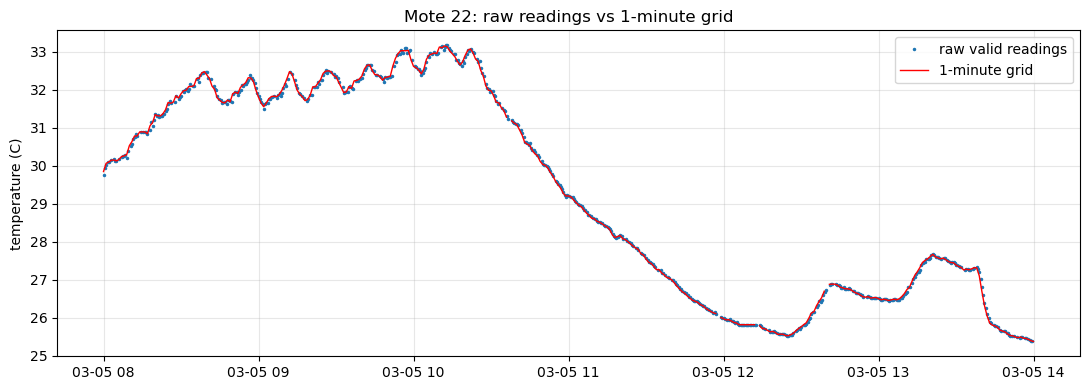

In [25]:
# (a) Raw readings vs 1-minute grid for one busy mote over 6 hours
m = int(records.groupby("moteid").size().idxmax())
a, b = pd.Timestamp("2004-03-05 08:00"), pd.Timestamp("2004-03-05 14:00")
r = records[(records["moteid"] == m) & records["timestamp"].between(a, b)]
g = grid[(grid["moteid"] == m) & grid["timestamp"].between(a, b)]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(r["timestamp"], r["temperature_clean"], ".", ms=3, label="raw valid readings")
ax.plot(g["timestamp"], g["temperature_clean"], "-", lw=1, color="red", label="1-minute grid")
ax.set_title(f"Mote {m}: raw readings vs 1-minute grid"); ax.set_ylabel("temperature (C)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "before_after_resampling.png"); plt.show()

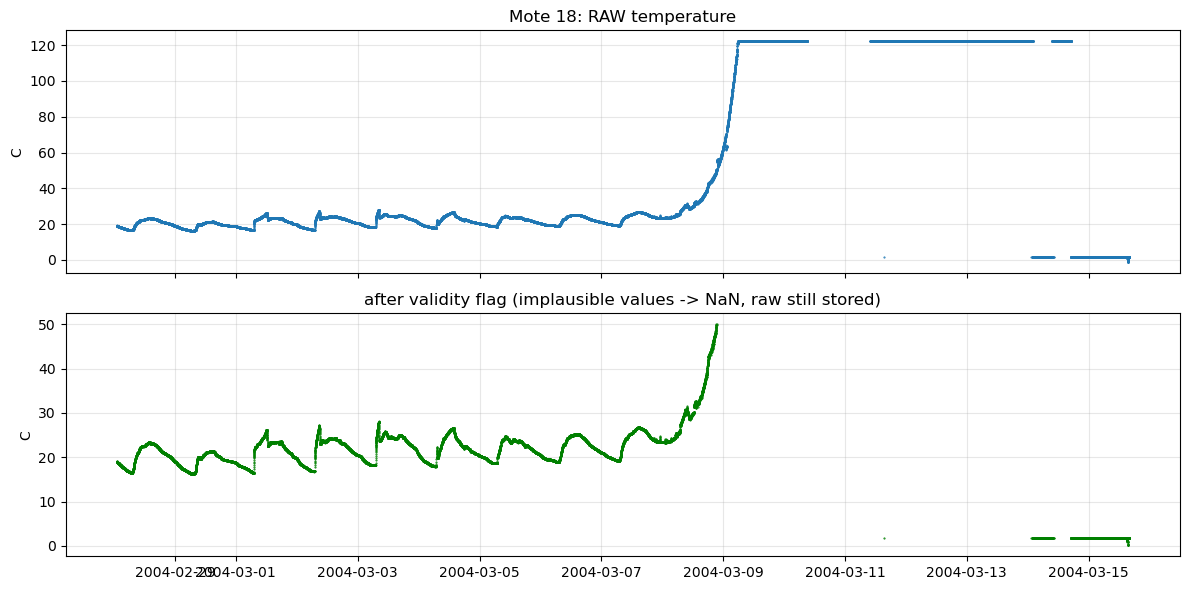

Mote 18: 27.6% of temperature readings flagged invalid


In [26]:
# (b) Effect of the validity flags on a mote that has implausible values
bad_share = records.groupby("moteid")["temperature_valid"].apply(lambda s: 1 - s.mean())
m2 = int(bad_share[records.groupby("moteid").size() > 5000].idxmax())
d = records[records["moteid"] == m2]
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(d["timestamp"], d["temperature"], ".", ms=1); axes[0].set_title(f"Mote {m2}: RAW temperature")
axes[1].plot(d["timestamp"], d["temperature_clean"], ".", ms=1, color="green")
axes[1].set_title("after validity flag (implausible values -> NaN, raw still stored)")
for ax in axes: ax.set_ylabel("C")
fig.tight_layout(); fig.savefig(FIG / "before_after_validity.png"); plt.show()
print(f"Mote {m2}: {100*bad_share[m2]:.1f}% of temperature readings flagged invalid")

### 🔎 Interpretation — Effect of validity filtering

For the selected high-coverage mote, **27.6% of its temperature readings are flagged invalid** under the configured physical plausibility rule.

The important part of this plot is that the invalid values are converted to `NaN` in `temperature_clean`, while the original raw temperature remains available.

That is preferable to deleting the entire sensor record because the abnormal measurement may later help identify a fault.

**Research meaning:** this notebook creates a clean analytical signal without erasing evidence about sensor quality.

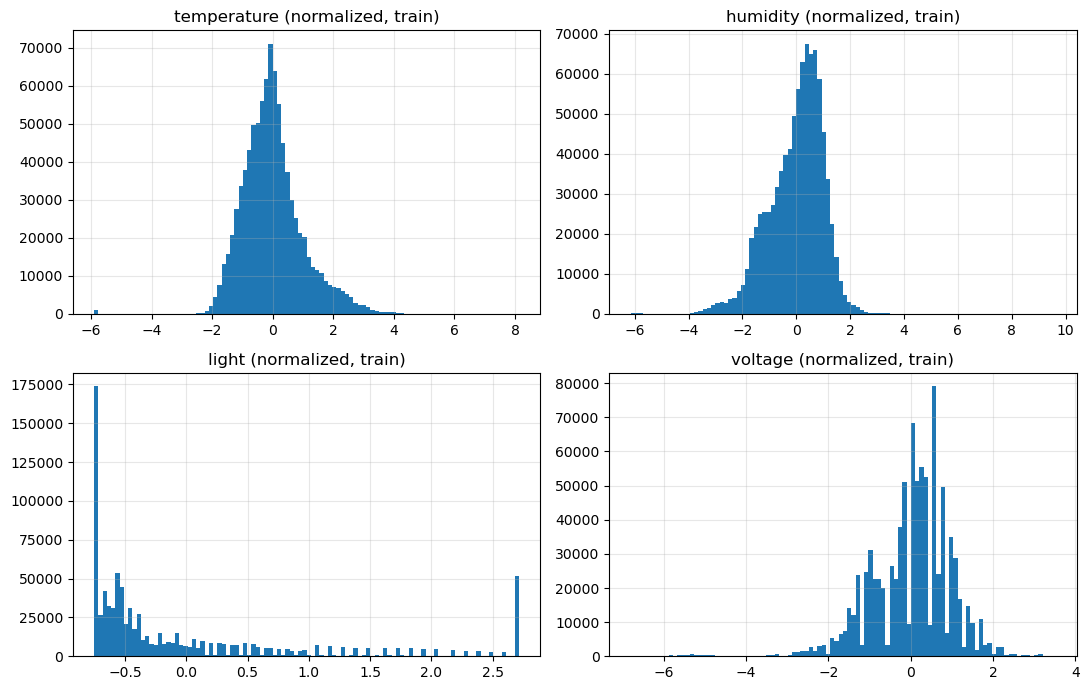

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, v in zip(axes.ravel(), u.MEASUREMENTS):
    ax.hist(grid.loc[is_train, f"{v}_norm"].dropna(), bins=100)
    ax.set_title(f"{v} (normalized, train)")
fig.tight_layout(); fig.savefig(FIG / "normalized_distributions.png"); plt.show()

### 🔎 Interpretation — Normalized distributions

These histograms show the distributions of the four normalized variables using **training data only**.

The expected result is approximately centered/scaled training distributions rather than identical shapes. Z-score normalization does **not** make the data Gaussian; it only rescales each variable using its training mean and standard deviation.

The distributions should therefore be interpreted as evidence that the scaling was applied, not as proof that the sensor variables follow normal distributions.

**Embedded/ML meaning:** normalization makes differently scaled physical variables easier to use together in later lightweight models, while the original physical-unit columns remain available.

## 9. Save processed data

In [31]:
final_cols = (["moteid", "timestamp", "split", "n_raw_records"]
              + clean_cols + [f"{v}_norm" for v in u.MEASUREMENTS])
clean_sensor_data = grid[final_cols].sort_values(["moteid", "timestamp"]).reset_index(drop=True)
clean_sensor_data.to_parquet(PROC / "clean_sensor_data.parquet", index=False)

metadata = {
    "seed": SEED, "grid_freq": GRID_FREQ, "end_time_exclusive": str(END_TIME),
    "split_fractions": SPLIT_FRACTIONS,
    "split_boundaries": {"train_end": str(train_end), "validation_end": str(val_end), "test_end": str(t1)},
    "valid_ranges": u.VALID_RANGES, "interpolation": "none", "noise_filtering": "none",
    "duplicate_policy": "keep first (moteid, timestamp)",
    "raw_rows": n_raw, "records_kept": len(records), "grid_rows": len(clean_sensor_data),
    "raw_sha256": RAW_HASH_BEFORE,
}
with open(PROC / "preprocessing_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print("saved:", [p.name for p in sorted(PROC.glob("*"))])

saved: ['clean_sensor_data.parquet', 'normalization_parameters.json', 'preprocessing_metadata.json']


### 🔎 Interpretation — Saved processed dataset

Three artifacts were successfully created:

- `clean_sensor_data.parquet` — the main one-minute, mote-aligned dataset.
- `normalization_parameters.json` — the training-only scaling parameters.
- `preprocessing_metadata.json` — configuration, split boundaries, validity ranges, record counts, and raw-data provenance.

The processed table contains:

- `moteid`
- `timestamp`
- `split`
- `n_raw_records`
- cleaned physical measurements
- normalized measurements

This is the correct handoff format for Notebook 3 because the physical-unit cleaned values are preserved for scenario injection.

## 10. Validation checks (reloads the saved files)

In [34]:
chk = pd.read_parquet(PROC / "clean_sensor_data.parquet")
with open(PROC / "normalization_parameters.json") as f:
    params = json.load(f)["parameters"]

# raw untouched
assert sha256(RAW_FILE) == RAW_HASH_BEFORE, "Raw file changed!"
# structure
assert list(chk.columns) == final_cols
assert len(chk) == 54 * len(grid_times)
assert not chk.duplicated(["moteid", "timestamp"]).any()
assert chk.groupby("moteid")["timestamp"].apply(lambda s: s.is_monotonic_increasing).all()
assert (chk.groupby("moteid")["timestamp"].count() == len(grid_times)).all()
# no data lost in binning
assert chk["n_raw_records"].sum() == len(records)
# physical values within plausible ranges, no infinities
for v in u.MEASUREMENTS:
    lo, hi = u.VALID_RANGES[v]
    s = chk[f"{v}_clean"].dropna()
    assert s.between(lo, hi).all(), f"{v}_clean has out-of-range values"
    assert np.isfinite(chk[f"{v}_norm"].dropna()).all()
# chronological split: train strictly before validation strictly before test
tmax = chk.groupby("split")["timestamp"].max(); tmin = chk.groupby("split")["timestamp"].min()
assert tmax["train"] < tmin["validation"] and tmax["validation"] < tmin["test"]
# normalization: train mean ~ 0, std ~ 1 ; and params equal a fresh train-only recompute
tr = chk[chk["split"] == "train"]
for v in u.MEASUREMENTS:
    assert abs(tr[f"{v}_norm"].mean()) < 1e-3, v
    assert abs(tr[f"{v}_norm"].std(ddof=0) - 1) < 1e-3, v
    assert abs(params[v]["mean"] - tr[f"{v}_clean"].astype("float64").mean()) < 1e-2 * max(1, abs(params[v]["mean"]))
# outputs exist
for p in [OUT / n for n in ["preprocessing_summary.csv", "missingness_before_after.csv"]] + \
         [FIG / n for n in ["before_after_resampling.png", "before_after_validity.png", "normalized_distributions.png"]] + \
         [PROC / n for n in ["clean_sensor_data.parquet", "normalization_parameters.json", "preprocessing_metadata.json"]]:
    assert p.stat().st_size > 0, p
print("ALL NOTEBOOK 2 CHECKS PASSED")
print(chk.head())

ALL NOTEBOOK 2 CHECKS PASSED
   moteid           timestamp  split  n_raw_records  temperature_clean  \
0       1 2004-02-28 00:58:00  train              0                NaN   
1       1 2004-02-28 00:59:00  train              1            19.9884   
2       1 2004-02-28 01:00:00  train              0                NaN   
3       1 2004-02-28 01:01:00  train              0                NaN   
4       1 2004-02-28 01:02:00  train              0                NaN   

   humidity_clean  light_clean  voltage_clean  temperature_norm  \
0             NaN          NaN            NaN               NaN   
1         37.0933    45.080002        2.69964         -0.587526   
2             NaN          NaN            NaN               NaN   
3             NaN          NaN            NaN               NaN   
4             NaN          NaN            NaN               NaN   

   humidity_norm  light_norm  voltage_norm  
0            NaN         NaN           NaN  
1      -0.276008   -0.667915     

### ✅ Interpretation — Notebook 2 validation

**ALL NOTEBOOK 2 CHECKS PASSED.**

The validation confirms that:

- the raw file was not modified;
- the saved schema matches the expected schema;
- every mote has the complete one-minute grid;
- `(moteid, timestamp)` is unique;
- timestamps are chronologically ordered per mote;
- no raw records were silently lost during the minute-binning step;
- cleaned physical values stay inside the configured plausibility ranges;
- normalized values are finite;
- the chronological train/validation/test ordering is valid;
- normalization parameters match a fresh train-only recomputation;
- all expected output files exist and are non-empty.

The displayed first rows also confirm an important behavior: a minute with no observation remains a row with `NaN`, rather than being filled with an artificial value.

**Decision:** Notebook 2 is operationally successful and produces a reproducible preprocessing baseline for Notebook 3.

## Result
`data/processed/clean_sensor_data.parquet` is one row per **mote × minute** with physical-unit `*_clean` columns (NaN where missing or implausible), z-scored `*_norm` columns (train-only statistics), `split` (train / validation / test by time), and `n_raw_records` (how many raw readings fed that minute).  
Notebook 3 builds the Normal / Drift / Event / Event+Drift scenarios on top of the `*_clean` columns.

## Research handoff to Notebook 3

### What Notebook 2 establishes

1. A documented, timestamp-valid subset is used for the primary baseline.
2. The late-deployment network degradation is excluded **by an explicit cutoff**, not silently discarded.
3. Raw sensor values are preserved, while separate validity flags and cleaned values are created.
4. Missing observations remain missing; **no interpolation** is performed.
5. The data is aligned to a common one-minute mote × time grid.
6. The split is chronological, reducing future-information leakage.
7. Normalization is fitted on training data only.
8. The processed dataset is reproducible and reloadable.
9. The raw dataset remains unchanged and traceable through its SHA-256 hash.

### What Notebook 2 does **not** establish

- It does not prove that every invalid measurement is a sensor fault.
- It does not prove that the 22 March cutoff is the only correct baseline boundary; it is a deliberate modeling choice based on Notebook 1's observed degradation.
- It does not interpolate or reconstruct missing measurements.
- It does not create fault labels.
- It does not yet distinguish environmental events from sensor-specific faults.

### Why this is appropriate for the embedded-systems project

The preprocessing stage produces a representation that is suitable for later lightweight edge reasoning:

**raw observation → quality state → time-aligned signal → later window/features → fault/event attribution**

The pipeline avoids heavy imputation and preserves physical-unit measurements, which keeps the later fault simulation and embedded interpretation grounded in actual sensor behavior.

### Handoff to Notebook 3

Notebook 3 should build the **Normal / Drift / Event / Event+Drift** scenarios on the `*_clean` physical-unit signals, while keeping the scenario-generation process reproducible and clearly separating **real observations** from **synthetically injected labels/scenarios**.
